# BloodLink – Exploratory Data Analysis

## Smart Blood Bank Network & Availability Platform

**Stage:** Exploratory Data Analysis (EDA)

**Dataset:** India Blood Bank Directory

**Objective:** To understand blood bank distribution, categories, geographical coverage and data availability across India, with detailed analysis of Karnataka.

## Step 1 : Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Step 2 : Load the cleaned data

In [5]:
from pathlib import Path

BASE_DIR = Path.cwd()

file_path = BASE_DIR / "dataset" / "cleaned" / "blood_banks_cleaned.csv"

# Resolve the dataset path robustly when the notebook sits inside a subfolder
file_path = Path(file_path)

if not file_path.exists():
    candidate = BASE_DIR.parent / "dataset" / "cleaned" / "blood_banks_cleaned.csv"
    if candidate.exists():
        file_path = candidate
    else:
        raise FileNotFoundError(
            f"Dataset not found. Checked: {file_path} and {candidate}"
        )

print("Dataset loaded successfully!")
data = pd.read_csv(file_path)
print("Total Records:", data.shape[0])
print("Total Columns:", data.shape[1])

Dataset loaded successfully!
Total Records: 2823
Total Columns: 15


In [6]:
display(data.head(10))

,state,district,city,name,address,pin,phone,helpline,website,category,components,apheresis,hours,lat,lon
0,andaman-and-nicobar-islands,South Andaman,Port Blair,G.B. Pant Hospital Blood bank,"Atlanta Point, Near Cellular Jail, P.O. Aberde...",744104.0,03192 230628,102,NaN,Government,True,False,24x7,11.67544,92.74734
1,andaman-and-nicobar-islands,South Andaman,Port Blair,I.N.H.S. Dhanvantri,"Ashvini Nagar, Port Blair, Andaman and Nicobar...",744103.0,03192 248759,NaN,NaN,Government,False,False,24x7,11.64969,92.71742
2,andaman-and-nicobar-islands,South Andaman,Port Blair,Pillar Health Centre Blood Bank,"Lamba Line, P.B. 526, P.O. Junglighat, Opposit...",744104.0,"03192 233193, 03192 233993",03192 233193,NaN,Charity,False,False,24x7,11.65323,92.73071
3,andhra-pradesh,Anantapur,Anantapur,"Indian Red Cross Society Blood Bank, District ...","Near JNTU Engeneering College, Sarada Nagar, A...",515002.0,08554 246344,NaN,NaN,Charity,True,False,24x7,14.65494,77.60992
4,andhra-pradesh,Anantapur,Ananthapur,Government General Hospital Blood Bank,"Government General Hospital, Ananthapur",515001.0,08554 275024,NaN,NaN,Government,True,False,24x7,14.67146,77.59668
5,andhra-pradesh,Anantapur,Ananthapur,Indian Red Cross Society,"Blood Bank Medical Officer,Blood Bank, Indian ...",515001.0,8554246344,NaN,NaN,Charity,True,False,24x7,14.68189,77.60059
6,andhra-pradesh,Anantapur,Bathalapalli,Rural Development Trust Hospital Blood Bank,"Kadiri Road, Bathalapalli, Ananthapur",515661.0,08559 244259,NaN,NaN,Charity,True,False,24x7,14.65291,77.61883
7,andhra-pradesh,Anantapur,Guntakal,South Central Railway Hospital Blood Bank,"S.C. Railway Hospital, Guntakal, Ananthapuramu",515801.0,08552 227166,NaN,NaN,Government,False,False,24x7,15.17289,77.36610
8,andhra-pradesh,Anantapur,Hindupur,Indian Red Cross Society Blood Bank,"Government General Hospital Blood Bank, Hindup...",515201.0,08556 225900,NaN,NaN,Charity,False,False,24x7,13.83253,77.49221
9,andhra-pradesh,Anantapur,Kadiri,Indian Red Cross Society Blood bank RCH -II KA...,"Ground Floor, APVVP (Government General Hospit...",515591.0,08494 221544,NaN,NaN,Government,False,False,24x7,14.11309,78.15737


In [7]:
data.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
state,2823,35,maharashtra,332,NaN,NaN,NaN,NaN,NaN,NaN,NaN
district,2823,600,Hyderabad,69,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,2803,1109,Mumbai,66,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,2823,2489,District Hospital Blood Bank,94,NaN,NaN,NaN,NaN,NaN,NaN,NaN
address,2751,2699,District Hospital,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pin,2628.0,NaN,NaN,NaN,485566.675419,204088.996504,110001.0,342003.0,500029.0,637052.0,855108.0
phone,2524,2518,079 27413719,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
helpline,202,200,1910,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
website,579,554,http://www.indianredcross.ap.org,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,2744,3,Government,1055,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Step 3 : Check the unique values

In [8]:
print("Number of States:", data["state"].nunique())

print("Number of Districts:", data["district"].nunique())

print("Number of Cities:", data["city"].nunique())

print("Number of Blood Bank Categories:", data["category"].nunique())

Number of States: 35
Number of Districts: 600
Number of Cities: 1109
Number of Blood Bank Categories: 3


## Step 4 : Blood bank distribution by state

In [9]:
state_count = data["state"].value_counts()

display(state_count.to_frame(name="Number of Blood Banks"))

,Number of Blood Banks
state,
maharashtra,332
tamil-nadu,291
uttar-pradesh,288
karnataka,198
kerala,179
telangana,149
andhra-pradesh,139
madhya-pradesh,139
gujarat,136


## Step 5 : Visualize state-wise distribution

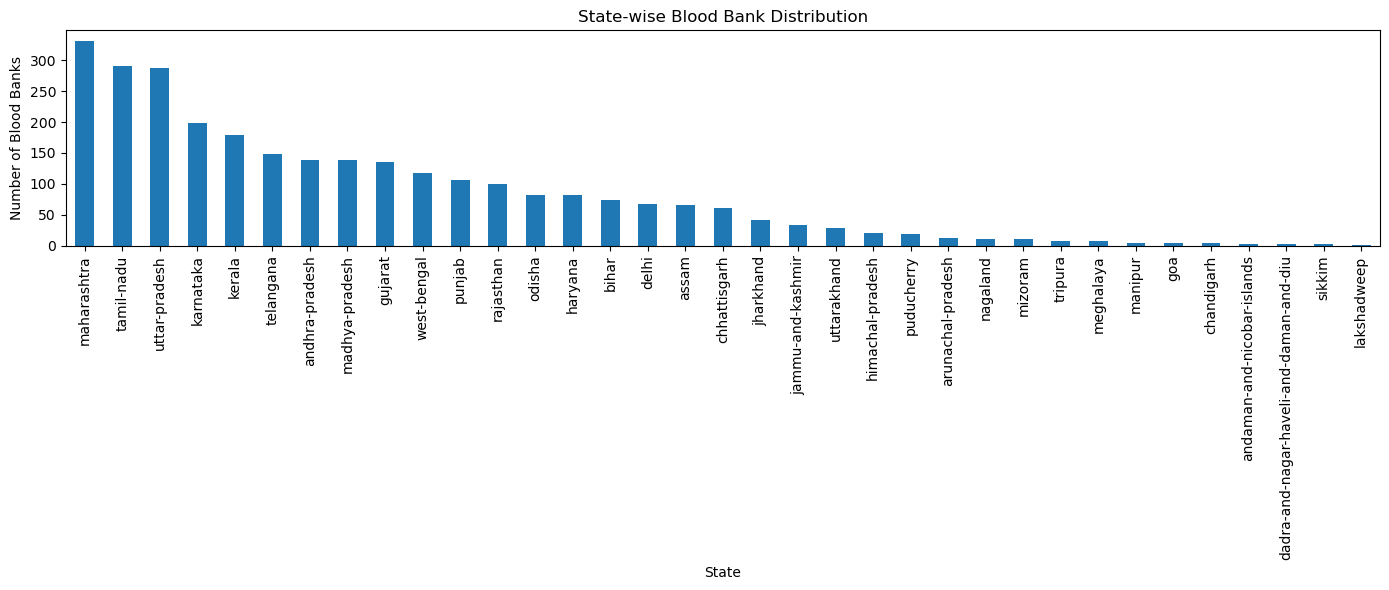

In [10]:
plt.figure(figsize=(14, 6))

state_count.plot(kind="bar")

plt.title("State-wise Blood Bank Distribution")
plt.xlabel("State")
plt.ylabel("Number of Blood Banks")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

## Step 6 : Top 10 states

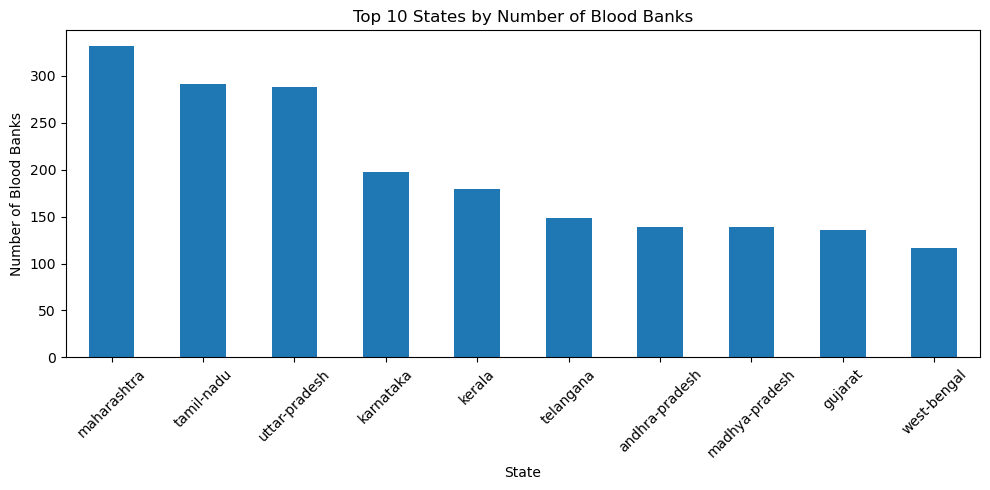

In [11]:
top_states = state_count.head(10)

plt.figure(figsize=(10, 5))

top_states.plot(kind="bar")

plt.title("Top 10 States by Number of Blood Banks")
plt.xlabel("State")
plt.ylabel("Number of Blood Banks")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Step 7 :  Blood bank category distribution

In [12]:
category_count = data["category"].value_counts(dropna=False)

display(category_count.to_frame(name="Number of Blood Banks"))

,Number of Blood Banks
category,
Government,1055
Private,999
Charity,690
NaN,79


## Step 8 : Category distribution chart

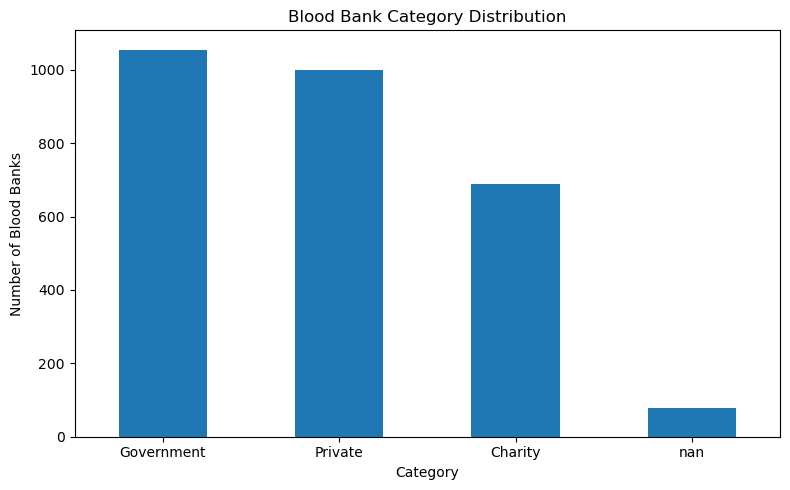

In [13]:
plt.figure(figsize=(8, 5))

category_count.plot(kind="bar")

plt.title("Blood Bank Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Blood Banks")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

## Step 9 : District-wise distribution

In [14]:
district_count = data["district"].value_counts()

print("Top 15 Districts by Blood Bank Count:")

display(district_count.head(15).to_frame(
    name="Number of Blood Banks"
))

Top 15 Districts by Blood Bank Count:


,Number of Blood Banks
district,
Hyderabad,69
Mumbai,66
Bengaluru Urban,62
Chennai,50
Kolkata,39
Pune,32
Thane,31
Lucknow,29
Indore,28


## Step 10 : Top 10 districts chart

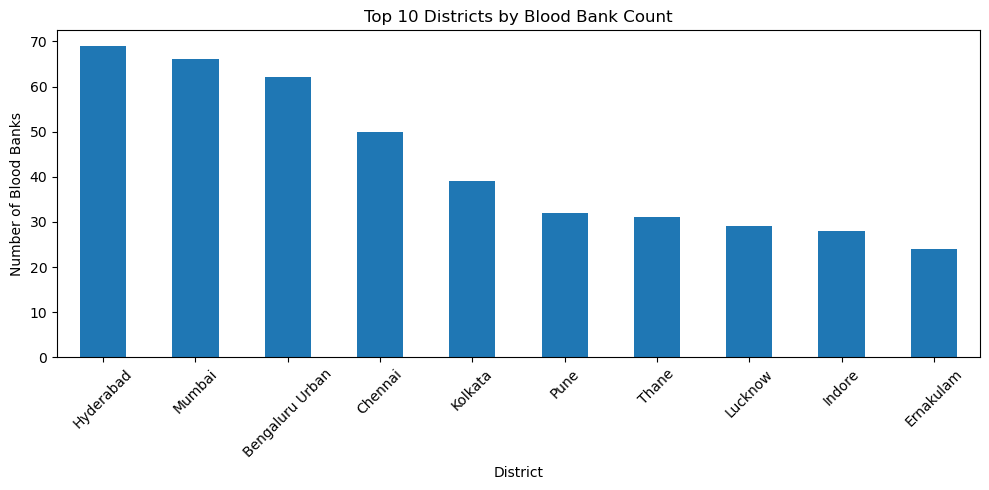

In [15]:
top_districts = district_count.head(10)

plt.figure(figsize=(10, 5))

top_districts.plot(kind="bar")

plt.title("Top 10 Districts by Blood Bank Count")
plt.xlabel("District")
plt.ylabel("Number of Blood Banks")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Step 11 : Filter Karnataka records

In [16]:
karnataka_data = data[
    data["state"].str.strip().str.lower() == "karnataka"
].copy()

print("Total Blood Banks in Karnataka:", len(karnataka_data))

display(karnataka_data.head())

Total Blood Banks in Karnataka: 198


,state,district,city,name,address,pin,phone,helpline,website,category,components,apheresis,hours,lat,lon
750,karnataka,Bagalkot,Bagalkot,B. V. V. Sanghas HSK Hospital Blood Bank,"Navanagar, Bagalkot",587102.0,08352 235410,NaN,NaN,Private,True,True,24x7,16.16508,75.67507
751,karnataka,Bagalkot,Bagalkot,Bagalkot Blood Bank,Hanagal Shree Kumareshwar Hospital and Researc...,587101.0,0835 220420,NaN,NaN,Private,False,False,24x7,16.18613,75.70653
752,karnataka,Bagalkot,Bagalkot,District Hospital Blood Bank Bagalkot,Navanagar,587101.0,0835 4236030,NaN,NaN,Government,False,False,24x7,16.16501,75.66081
753,karnataka,Bagalkot,Ilkal,M/s. Vijay Mahant Blood Bank,Sri Basaveshwara Childrens Hospital & Research...,587125.0,08351 270838,NaN,NaN,Private,True,False,24x7,NaN,NaN
754,karnataka,Bagalkot,Jamkhandi,Mounesh Hospital's The Jhamkandi Blood Bank,"Near P.B. High School, Uma Rameshwar Road",587101.0,08353 22357,NaN,NaN,Private,False,False,24x7,NaN,NaN


## Step 12 : Karnataka district-wise distribution

In [17]:
karnataka_districts = karnataka_data["district"].value_counts()

display(
    karnataka_districts.to_frame(
        name="Number of Blood Banks"
    )
)

,Number of Blood Banks
district,
Bengaluru Urban,62
Dakshina Kannada,16
Mysore,13
Dharwad,11
Belgaum,7
Bagalkot,7
Shivamogga,7
Kalaburagi,6
Davangere,6


## Step 13 : Karnataka district chart

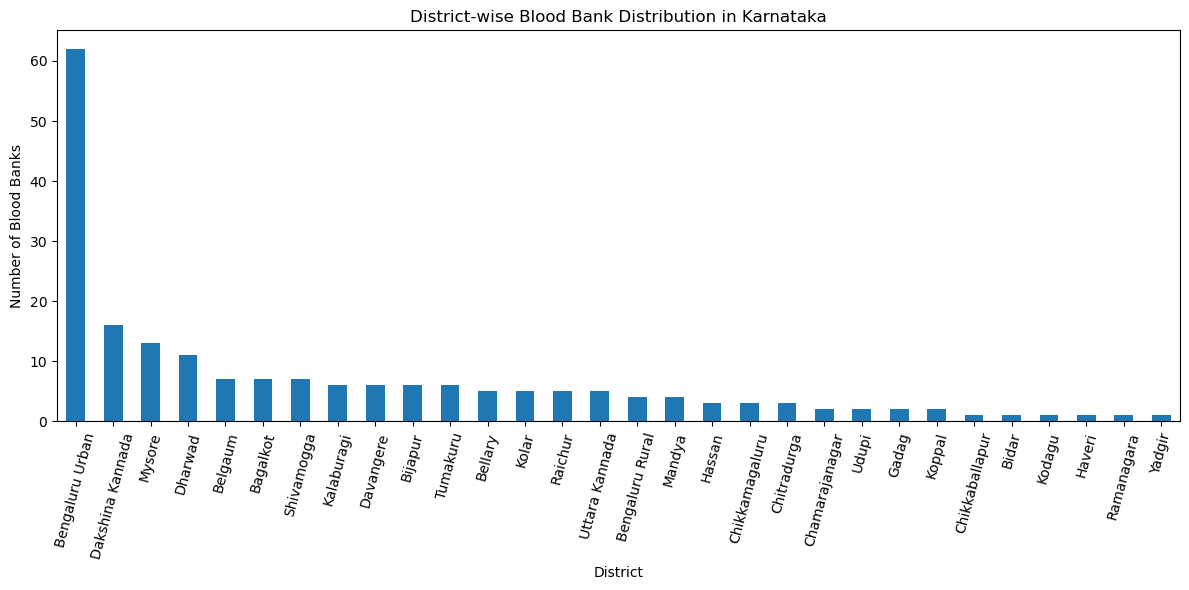

In [18]:
plt.figure(figsize=(12, 6))

karnataka_districts.plot(kind="bar")

plt.title("District-wise Blood Bank Distribution in Karnataka")
plt.xlabel("District")
plt.ylabel("Number of Blood Banks")
plt.xticks(rotation=75)

plt.tight_layout()
plt.show()

## Step 14 : Geographic data availability

In [19]:
valid_coordinates = data.dropna(subset=["lat", "lon"])

missing_coordinates = data[
    data["lat"].isna() | data["lon"].isna()
]

print("Records with Coordinates:", len(valid_coordinates))

print("Records without Complete Coordinates:", len(missing_coordinates))

Records with Coordinates: 2439
Records without Complete Coordinates: 384
